# 미니프로젝트 6: Day 1~6 통합 복습 (Vibe Coding)

#### <목표>
Day1 ~ 6에서 배운 머신러닝 프로세스 전체를 새로운 데이터셋(신용카드 고객 채무불이행)에 자유롭게 적용해 봅니다.

**Cursor AI**를 활용하여 각 단계의 코드를 직접 생성하고 실행해 보세요.

#### <데이터셋 소개>
- Default of Credit Card Clients (대만 신용카드 고객 채무불이행 데이터)
- 30,000명의 신용카드 고객 정보로 다음 달 채무불이행 여부를 예측

| 변수명 | 설명 |
|:---:|:---|
| LIMIT_BAL | 신용한도 |
| SEX, EDUCATION, MARRIAGE, AGE | 고객 인적사항 |
| PAY_0, PAY_2~PAY_6 | 최근 6개월 월별 연체 상태 (-1: 정상납부, 1 이상: 연체 개월 수) |
| BILL_AMT1~6 | 최근 6개월 청구액 |
| PAY_AMT1~6 | 최근 6개월 납부액 |
| default payment next month | 다음 달 채무불이행 여부 (1: 불이행, 0: 정상) |

#### <실습 태스크>
| 태스크 | 타겟 변수 | 설명 |
|:---:|:---:|:---|
| 분류 | `default payment next month` | 고객 정보로 다음 달 채무불이행 여부 예측 |

1. 각 섹션의 **과제**를 읽고, Day1~6 중 어떤 내용을 적용해야 할지 먼저 생각해 봅니다.
2. 빈 코드 셀을 클릭한 후 Cursor AI 채팅창을 엽니다.
3. 막막한 부분은 AI와 상의해서 방법을 정하고, 그 방법으로 프롬프트를 작성합니다.
4. 생성된 코드를 실행하고 결과를 확인합니다.

## 0) 분석 준비

- `dataset/day6_miniproject.csv` 파일을 사용하기
- 타겟 변수: `default payment next month` (0: 정상, 1: 채무불이행)

**[과제]** 써니는 신용카드 고객 채무불이행 데이터를 분석하게 되었습니다. 분석에 필요한 라이브러리와 데이터를 불러오는 코드를 AI와 상의해서 작성하세요.

In [1]:
# ===== 1. 필요한 라이브러리 불러오기 =====
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams["font.family"] = "Malgun Gothic"   # Windows 기본 한글 폰트
plt.rcParams["axes.unicode_minus"] = False       # 마이너스 기호 깨짐 방지
sns.set_theme(style="whitegrid", font="Malgun Gothic")

# 머신러닝 라이브러리
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

# ===== 2. 데이터 불러오기 =====
df = pd.read_csv("dataset/day6_miniproject.csv")

# 데이터가 잘 불러와졌는지 확인
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1) 데이터 탐색 (EDA)

1. Value 기반 탐색 (구조적/통계적)
2. Graph 기반 탐색 (단일 변수/변수 간/여러 변수 간)

**[과제]** 써니는 모델링을 수행하기 전에 필요한 전처리 과정을 파악하기 위해 데이터 탐색(EDA)이 필요하다고 생각했습니다.

AI와 상의하여 데이터의 구조적 정보(변수 타입, 결측치 유무 등)와 통계적 정보(변수별 고유값 개수, 기초통계량 등)를 확인하는 코드를 작성하고, 결과를 분석해 보세요.


In [2]:
# ===== 1. 데이터 구조 확인 (각 컬럼의 타입, non-null 개수) =====
print("데이터 크기:", df.shape)
df.info()

데이터 크기: (7043, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 

In [3]:
# ===== 2. 컬럼별 타입 / 고유값 개수 / 결측치 요약 =====
summary = pd.DataFrame({
    "dtype": df.dtypes,                      # 데이터 타입
    "n_unique": df.nunique(),                # 고유값 개수
    "n_missing": df.isnull().sum(),          # 결측치 개수
    "missing_ratio(%)": (df.isnull().mean() * 100).round(2),  # 결측 비율
})
summary

,dtype,n_unique,n_missing,missing_ratio(%)
customerID,object,7043,0,0.0
gender,object,2,0,0.0
SeniorCitizen,int64,2,0,0.0
Partner,object,2,0,0.0
Dependents,object,2,0,0.0
tenure,int64,73,0,0.0
PhoneService,object,2,0,0.0
MultipleLines,object,3,0,0.0
InternetService,object,3,0,0.0
OnlineSecurity,object,3,0,0.0


In [4]:
# ===== 3. 기초 통계량 =====
# 수치형 변수 통계량 (평균, 표준편차, 사분위수 등)
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [5]:
# ===== 4. 범주형 변수의 실제 고유값 확인 (고유값이 적은 컬럼만) =====
for col in df.select_dtypes(include="object").columns:
    if df[col].nunique() <= 10:
        print(f"[{col}] ({df[col].nunique()}개): {df[col].unique().tolist()}")

[gender] (2개): ['Female', 'Male']
[Partner] (2개): ['Yes', 'No']
[Dependents] (2개): ['No', 'Yes']
[PhoneService] (2개): ['No', 'Yes']
[MultipleLines] (3개): ['No phone service', 'No', 'Yes']
[InternetService] (3개): ['DSL', 'Fiber optic', 'No']
[OnlineSecurity] (3개): ['No', 'Yes', 'No internet service']
[OnlineBackup] (3개): ['Yes', 'No', 'No internet service']
[DeviceProtection] (3개): ['No', 'Yes', 'No internet service']
[TechSupport] (3개): ['No', 'Yes', 'No internet service']
[StreamingTV] (3개): ['No', 'Yes', 'No internet service']
[StreamingMovies] (3개): ['No', 'Yes', 'No internet service']
[Contract] (3개): ['Month-to-month', 'One year', 'Two year']
[PaperlessBilling] (2개): ['Yes', 'No']
[PaymentMethod] (4개): ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
[Churn] (2개): ['No', 'Yes']


In [6]:
# TotalCharges를 float형으로 변환 (변환 불가 값은 NaN 처리 후 0으로 대체)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

# Churn을 Yes=1, No=0으로 변환
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# 변환 결과 확인
print(df["TotalCharges"].dtype)              # float64
print("결측치 개수:", df["TotalCharges"].isnull().sum())
print(df["Churn"].value_counts())            # 0/1 분포 확인

float64
결측치 개수: 0
Churn
0    5174
1    1869
Name: count, dtype: int64


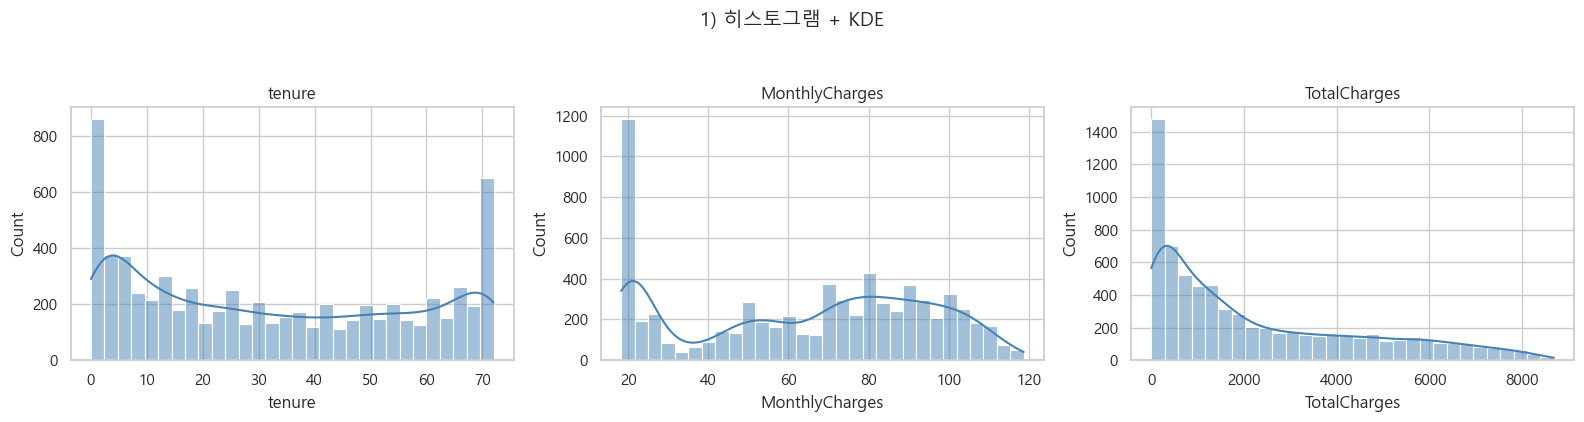

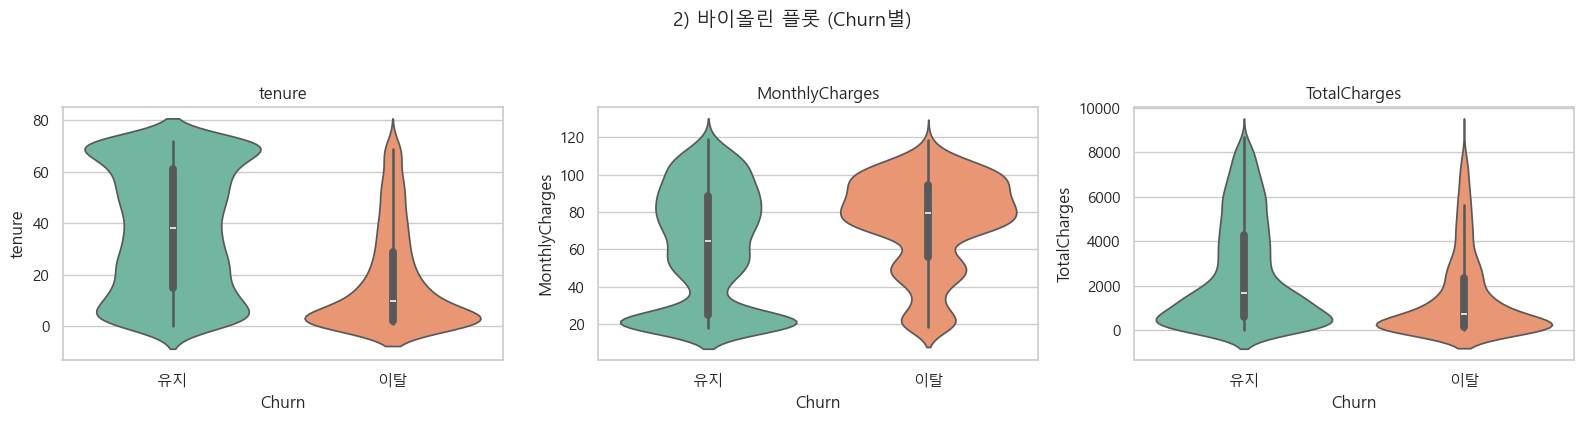

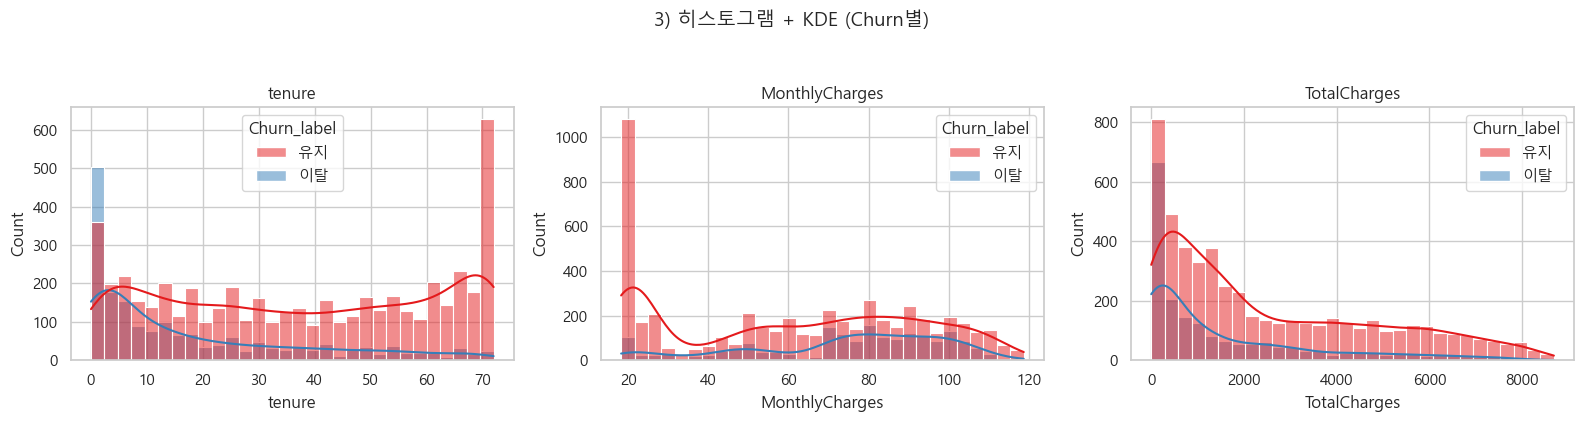

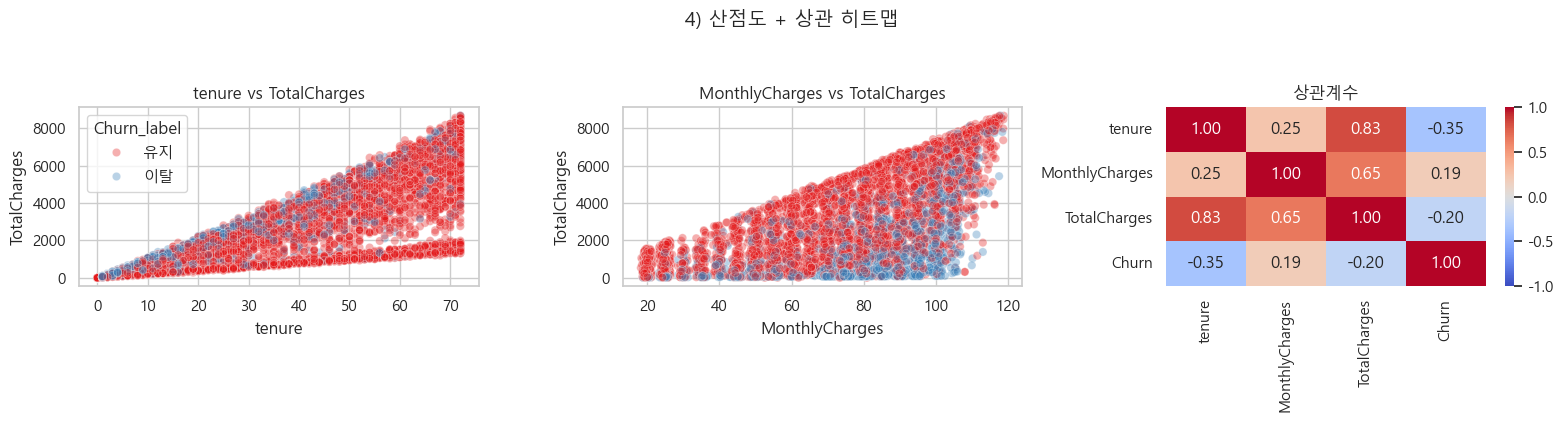

In [7]:
# ===== 연속형 변수 시각화 EDA (4종 × 1행 subplot) =====
num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]

df_eda = df.copy()
df_eda["Churn_label"] = df_eda["Churn"].map({0: "유지", 1: "이탈"})

# 1) 히스토그램 + KDE
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df_eda, x=col, kde=True, bins=30, ax=ax, color="steelblue", edgecolor="white")
    ax.set_title(col)
fig.suptitle("1) 히스토그램 + KDE", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

# 2) 바이올린 플롯 (Churn별 — 분포 형태 + 이상치)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.violinplot(
        data=df_eda, x="Churn_label", y=col, hue="Churn_label",
        ax=ax, palette="Set2", legend=False, inner="box"
    )
    ax.set_title(col)
    ax.set_xlabel("Churn")
fig.suptitle("2) 바이올린 플롯 (Churn별)", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

# 3) 히스토그램 + KDE (Churn별)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(
        data=df_eda, x=col, hue="Churn_label", kde=True, bins=30,
        ax=ax, alpha=0.5, palette="Set1"
    )
    ax.set_title(col)
fig.suptitle("3) 히스토그램 + KDE (Churn별)", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

# 4) 산점도 + 상관 히트맵
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.scatterplot(
    data=df_eda, x="tenure", y="TotalCharges",
    hue="Churn_label", alpha=0.35, ax=axes[0], palette="Set1"
)
axes[0].set_title("tenure vs TotalCharges")

sns.scatterplot(
    data=df_eda, x="MonthlyCharges", y="TotalCharges",
    hue="Churn_label", alpha=0.35, ax=axes[1], palette="Set1", legend=False
)
axes[1].set_title("MonthlyCharges vs TotalCharges")

corr = df_eda[num_cols + ["Churn"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[2], vmin=-1, vmax=1)
axes[2].set_title("상관계수")

fig.suptitle("4) 산점도 + 상관 히트맵", fontsize=14, y=1.05)
plt.tight_layout()
plt.show()

**[과제]** 써니는 데이터의 분포에 따라 필요한 전처리와 분석 방법이 달라질 수 있다고 생각했습니다.

AI와 상의하여 범주형 변수와 연속형 변수의 분포를 시각화하고 어떤 전처리와 분석이 필요한지 탐구해 보세요.

In [ ]:
# ===== 범주형 변수: Churn별 막대그래프 =====
df_eda = df.copy()
df_eda["Churn_label"] = df_eda["Churn"].map({0: "유지", 1: "이탈"})

cat_groups = {
    "인적": ["gender", "SeniorCitizen", "Partner", "Dependents"],
    "계약·결제": ["Contract", "PaperlessBilling", "PaymentMethod"],
    "통신": ["PhoneService", "MultipleLines", "InternetService"],
    "부가서비스": ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"],
}

for group_name, cols in cat_groups.items():
    fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols), 4))
    if len(cols) == 1:
        axes = [axes]

    for ax, col in zip(axes, cols):
        plot_df = df_eda.copy()
        if col == "SeniorCitizen":
            plot_df[col] = plot_df[col].map({0: "No", 1: "Yes"})

        sns.countplot(data=plot_df, x=col, hue="Churn_label", ax=ax, palette="Set1")
        ax.set_title(col)
        ax.tick_params(axis="x", rotation=30)
        ax.set_xlabel("")

    fig.suptitle(f"범주형 변수 — Churn별 분포 ({group_name})", fontsize=14, y=1.05)
    plt.tight_layout()
    plt.show()


# ===== 변수 간 관계: 교차표 =====
crosstab_pairs = [
    ("PhoneService", "MultipleLines"),
    ("InternetService", "OnlineSecurity"),
    ("InternetService", "TechSupport"),
    ("InternetService", "StreamingTV"),
    ("StreamingTV", "StreamingMovies"),
    ("Contract", "PaymentMethod"),
]

for col1, col2 in crosstab_pairs:
    print("=" * 60)
    print(f"[교차표] {col1} × {col2} — 빈도")
    display(pd.crosstab(df[col1], df[col2], margins=True))

    print(f"[교차표] {col1} × {col2} — {col1} 기준 비율(%)")
    display((pd.crosstab(df[col1], df[col2], normalize="index") * 100).round(1))

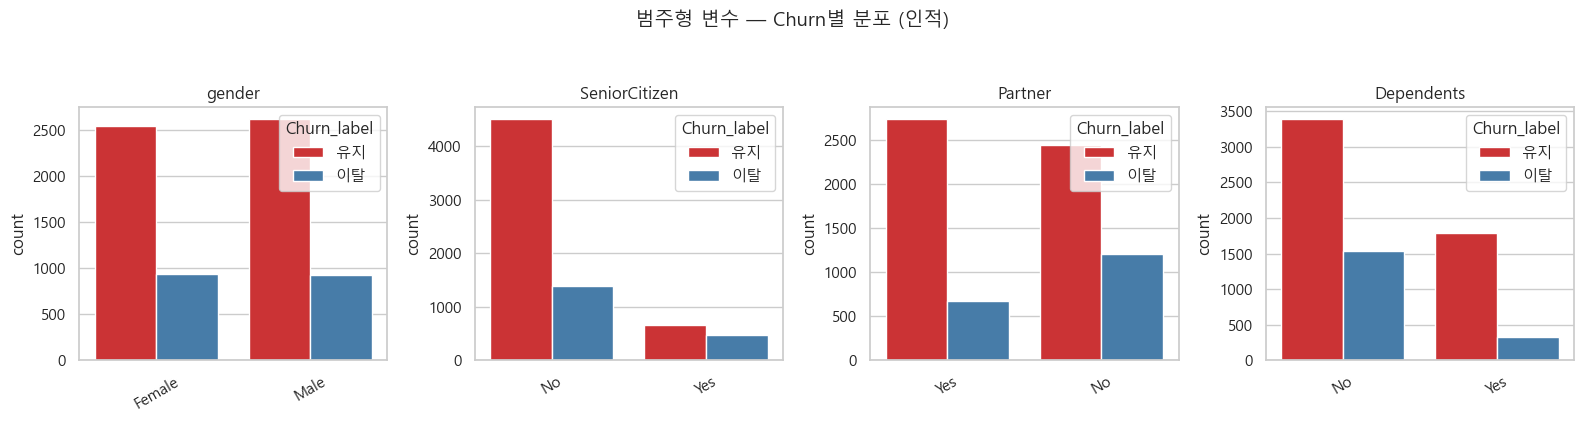

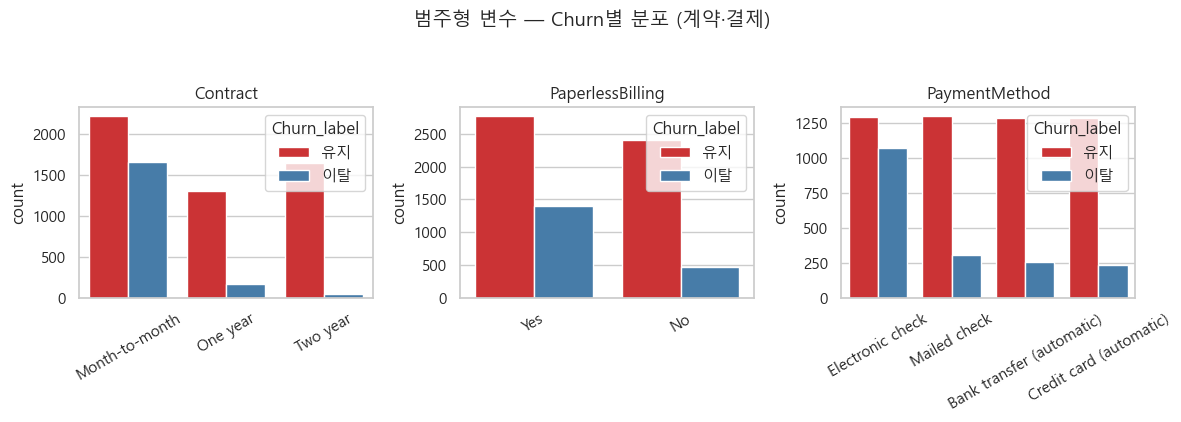

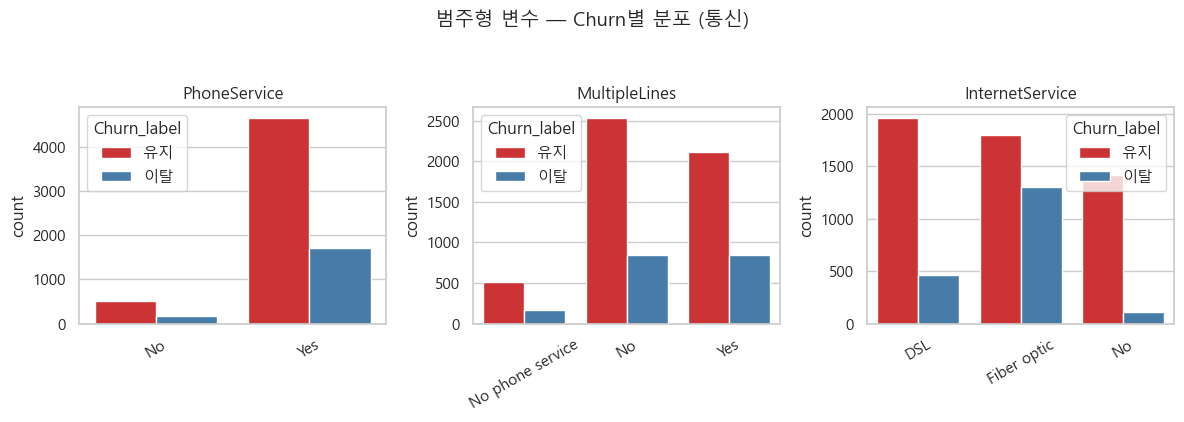

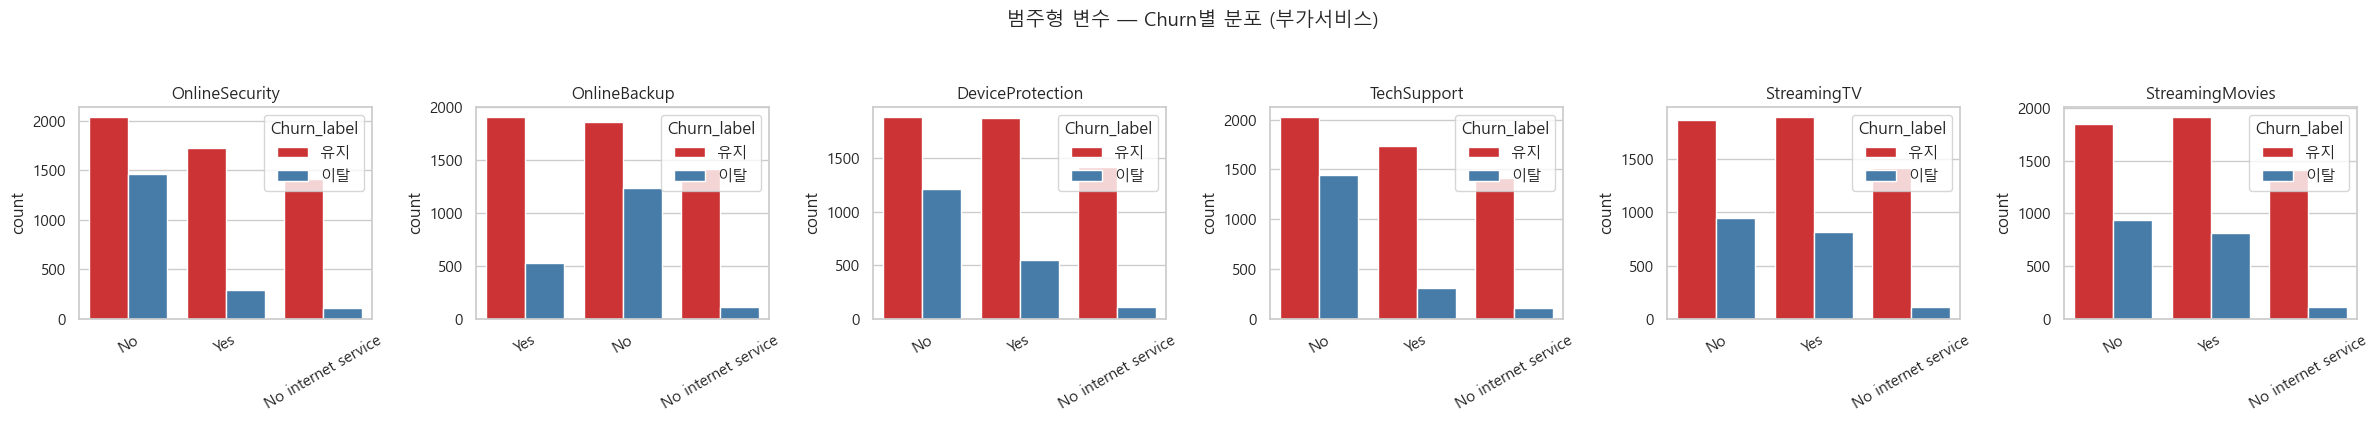

In [9]:
# ===== 범주형 변수: Churn별 막대그래프 =====
df_eda = df.copy()
df_eda["Churn_label"] = df_eda["Churn"].map({0: "유지", 1: "이탈"})

cat_groups = {
    "인적": ["gender", "SeniorCitizen", "Partner", "Dependents"],
    "계약·결제": ["Contract", "PaperlessBilling", "PaymentMethod"],
    "통신": ["PhoneService", "MultipleLines", "InternetService"],
    "부가서비스": ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"],
}

for group_name, cols in cat_groups.items():
    fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols), 4))
    if len(cols) == 1:
        axes = [axes]

    for ax, col in zip(axes, cols):
        plot_df = df_eda.copy()
        if col == "SeniorCitizen":
            plot_df[col] = plot_df[col].map({0: "No", 1: "Yes"})

        sns.countplot(data=plot_df, x=col, hue="Churn_label", ax=ax, palette="Set1")
        ax.set_title(col)
        ax.tick_params(axis="x", rotation=30)
        ax.set_xlabel("")

    fig.suptitle(f"범주형 변수 — Churn별 분포 ({group_name})", fontsize=14, y=1.05)
    plt.tight_layout()
    plt.show()



---

## 2) 데이터 전처리

1. 불필요한 변수 제거
2. 다중공선성 해결
3. 결측치 처리
4. 이상치 처리
5. 클래스 불균형 문제 해결
6. 스케일링/인코딩
7. 변수 내 데이터 값을 적절한 값으로 변경 (ex. "Yes" -> 1)

**[과제]** 써니는 EDA 결과를 바탕으로 모델링에 필요한 전처리 과정을 계획하고자 합니다.

AI와 상의하여 필요한 전처리 항목을 나열한 뒤, 학습 데이터와 테스트 데이터 분할 시점을 고려하여 분할 전에 수행해야 하는 전처리와 분할 후에 수행해야 하는 전처리를 구분해 보세요. 

이후 올바른 순서에 따라 전처리를 진행해 보세요.

In [10]:
# ===== 데이터 전처리 =====
df_prep = df.copy()

# 1) 불필요 변수 제거
# - customerID: 고유 식별자
# - TotalCharges: tenure와 다중공선성
df_prep = df_prep.drop(columns=["customerID", "TotalCharges"])

# 2) Churn은 이미 0/1 변환 완료 (확인만)
assert set(df_prep["Churn"].dropna().unique()).issubset({0, 1}), "Churn이 0/1이 아닙니다. 위 셀을 먼저 실행하세요."
print("Churn 분포:")
print(df_prep["Churn"].value_counts())

# 3) One-Hot Encoding 전 범주값 정리
# 상위 변수(PhoneService, InternetService)에서 이미 반영된 값은 "No"로 통일
df_prep["MultipleLines"] = df_prep["MultipleLines"].replace("No phone service", "No")

internet_addon_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
for col in internet_addon_cols:
    df_prep[col] = df_prep[col].replace("No internet service", "No")

# 4) X / y 분리
y = df_prep["Churn"]
X = df_prep.drop(columns=["Churn"])

# 5) One-Hot Encoding (범주형 object 컬럼만)
cat_cols = X.select_dtypes(include="object").columns.tolist()
num_cols = X.select_dtypes(exclude="object").columns.tolist()

X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=False)

# 결과 확인
print(f"\n제거·정리 후 원본 feature shape: {X.shape}")
print(f"수치형: {num_cols}")
print(f"범주형: {cat_cols}")
print(f"One-Hot Encoding 후 shape: {X_encoded.shape}")
X_encoded.head()

Churn 분포:
Churn
0    5174
1    1869
Name: count, dtype: int64

제거·정리 후 원본 feature shape: (7043, 18)
수치형: ['SeniorCitizen', 'tenure', 'MonthlyCharges']
범주형: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
One-Hot Encoding 후 shape: (7043, 37)


,SeniorCitizen,tenure,MonthlyCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,...,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,True,False,False,True,True,False,True,...,False,True,False,False,False,True,False,False,True,False
1,0,34,56.95,False,True,True,False,True,False,False,...,False,False,True,False,True,False,False,False,False,True
2,0,2,53.85,False,True,True,False,True,False,False,...,False,True,False,False,False,True,False,False,False,True
3,0,45,42.30,False,True,True,False,True,False,True,...,False,False,True,False,True,False,True,False,False,False
4,0,2,70.70,True,False,True,False,True,False,False,...,False,True,False,False,False,True,False,False,True,False


In [11]:
# ===== Train / Validation / Test 분할 (stratify로 Churn 비율 유지) =====
# 비율: Train 60% / Validation 20% / Test 20%
RANDOM_STATE = 42

# 1) Test 20% 분리
X_temp, X_test, y_temp, y_test = train_test_split(
    X_encoded, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

# 2) 나머지 80%를 Train 60% / Validation 20%로 분리
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp,
    test_size=0.25,  # 0.8 × 0.25 = 0.2
    random_state=RANDOM_STATE,
    stratify=y_temp,
)

# 분할 결과 및 클래스 비율 확인
def show_split_info(name, y_split):
    ratio = y_split.value_counts(normalize=True).sort_index()
    print(f"{name:12s} | n={len(y_split):5d} | 0(유지)={ratio[0]:.3f} | 1(이탈)={ratio[1]:.3f}")

print("전체 Churn 비율")
show_split_info("전체", y)
print()
print("분할 후 Churn 비율 (stratify 적용)")
show_split_info("Train", y_train)
show_split_info("Validation", y_val)
show_split_info("Test", y_test)

print(f"\nshape → Train: {X_train.shape}, Val: {X_val.shape}, Test: {X_test.shape}")

전체 Churn 비율
전체           | n= 7043 | 0(유지)=0.735 | 1(이탈)=0.265

분할 후 Churn 비율 (stratify 적용)
Train        | n= 4225 | 0(유지)=0.735 | 1(이탈)=0.265
Validation   | n= 1409 | 0(유지)=0.735 | 1(이탈)=0.265
Test         | n= 1409 | 0(유지)=0.735 | 1(이탈)=0.265

shape → Train: (4225, 37), Val: (1409, 37), Test: (1409, 37)


---

## 3) 모델링 및 모델 고도화

1. 단일 모델 (Logistic Regression, Decision Tree)
2. 앙상블 모델 (Random Forest, GBM, XGBoost, LightGBM, CatBoost)

**[과제]** 써니는 본 데이터에 가장 적합한 분류 모델이 무엇인지 알아보고자 합니다.

AI와 상의하여 다양한 분류 모델을 선정하고 학습시키는 코드를 작성한 뒤, Accuracy, Precision, Recall, F1-score, AUC-ROC 등의 분류 평가 지표를 활용하여 모델별 성능을 비교해 보세요.

In [12]:
# ===== 단일 모델: 로지스틱 회귀 & 의사결정나무 (GridSearchCV 최적화 + 성능 비교) =====
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ----- 평가 함수 -----
def get_metrics(y_true, y_pred, y_proba):
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall":    recall_score(y_true, y_pred, zero_division=0),
        "F1-score":  f1_score(y_true, y_pred, zero_division=0),
        "AUC-ROC":   roc_auc_score(y_true, y_proba),
    }

def evaluate_model(model, X, y):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    return get_metrics(y, y_pred, y_proba)

# ----- 1) 로지스틱 회귀 (스케일링 포함 Pipeline) -----
lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

lr_param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
}

lr_grid = GridSearchCV(
    estimator=lr_pipe,
    param_grid=lr_param_grid,
    cv=cv,
    scoring="roc_auc",      # 클래스 불균형 → Accuracy 대신 AUC 기준 탐색
    n_jobs=-1,
    refit=True,
)
lr_grid.fit(X_train, y_train)

print("[Logistic Regression] Best params:", lr_grid.best_params_)
print("[Logistic Regression] Best CV AUC-ROC:", round(lr_grid.best_score_, 4))

# ----- 2) 의사결정나무 -----
dt_param_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": [None, "balanced"],
}

dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=dt_param_grid,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    refit=True,
)
dt_grid.fit(X_train, y_train)

print("\n[Decision Tree] Best params:", dt_grid.best_params_)
print("[Decision Tree] Best CV AUC-ROC:", round(dt_grid.best_score_, 4))

# ----- 3) Validation 성능 비교 -----
best_models = {
    "Logistic Regression": lr_grid.best_estimator_,
    "Decision Tree": dt_grid.best_estimator_,
}

val_results = []
for name, model in best_models.items():
    metrics = evaluate_model(model, X_val, y_val)
    metrics["Model"] = name
    val_results.append(metrics)

val_df = (
    pd.DataFrame(val_results)
    .set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score", "AUC-ROC"]]
    .round(4)
)

print("\n===== Validation 성능 비교 =====")
display(val_df)

# ----- 4) Test 최종 평가 (참고용) -----
test_results = []
for name, model in best_models.items():
    metrics = evaluate_model(model, X_test, y_test)
    metrics["Model"] = name
    test_results.append(metrics)

test_df = (
    pd.DataFrame(test_results)
    .set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score", "AUC-ROC"]]
    .round(4)
)

print("\n===== Test 최종 성능 =====")
display(test_df)

[Logistic Regression] Best params: {'model__C': 10, 'model__class_weight': None}
[Logistic Regression] Best CV AUC-ROC: 0.8468

[Decision Tree] Best params: {'class_weight': 'balanced', 'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 2}
[Decision Tree] Best CV AUC-ROC: 0.8281

===== Validation 성능 비교 =====


,Accuracy,Precision,Recall,F1-score,AUC-ROC
Model,,,,,
Logistic Regression,0.8062,0.6689,0.5348,0.5944,0.8356
Decision Tree,0.7331,0.4983,0.7941,0.6124,0.8129



===== Test 최종 성능 =====


,Accuracy,Precision,Recall,F1-score,AUC-ROC
Model,,,,,
Logistic Regression,0.7984,0.6398,0.5508,0.5920,0.8387
Decision Tree,0.7431,0.5105,0.7807,0.6173,0.8277


In [13]:
# ===== 앙상블 모델 개별 최적화 (Loop) + 최종 성능 =====
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)  # 실습용: 3-fold (시간 절약)

# 클래스 불균형 보정용 (XGBoost)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# ----- 평가 함수 -----
def get_metrics(y_true, y_pred, y_proba):
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall":    recall_score(y_true, y_pred, zero_division=0),
        "F1-score":  f1_score(y_true, y_pred, zero_division=0),
        "AUC-ROC":   roc_auc_score(y_true, y_proba),
    }

def evaluate_model(model, X, y):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    return get_metrics(y, y_pred, y_proba)

# ----- 모델별 탐색 공간 -----
model_configs = {
    "Random Forest": {
        "estimator": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        "param_grid": {
            "max_depth": [5, 7, 10, None],
            "min_samples_leaf": [2, 4, 8],
            "n_estimators": [100, 300],
            "max_features": ["sqrt", 0.5],
            "class_weight": [None, "balanced"],
        },
    },
    "GBM": {
        "estimator": GradientBoostingClassifier(random_state=RANDOM_STATE),
        "param_grid": {
            "n_estimators": [100, 300],
            "learning_rate": [0.01, 0.05, 0.1],
            "max_depth": [3, 5],
            "min_samples_leaf": [1, 5],
            "subsample": [0.8, 1.0],
        },
    },
    "XGBoost": {
        "estimator": XGBClassifier(
            random_state=RANDOM_STATE,
            eval_metric="logloss",
            scale_pos_weight=scale_pos_weight,
            n_jobs=-1,
        ),
        "param_grid": {
            "n_estimators": [100, 300],
            "learning_rate": [0.01, 0.05, 0.1],
            "max_depth": [3, 5],
            "gamma": [0, 2],
            "reg_lambda": [1, 5],
            "subsample": [0.8, 1.0],
        },
    },
    "LightGBM": {
        "estimator": LGBMClassifier(
            random_state=RANDOM_STATE,
            subsample_freq=1,
            verbose=-1,
            class_weight="balanced",
        ),
        "param_grid": {
            "n_estimators": [100, 300],
            "learning_rate": [0.01, 0.05, 0.1],
            "max_depth": [3, 5],
            "num_leaves": [15, 31],
            "min_child_samples": [20, 50],
            "subsample": [0.8, 1.0],
        },
    },
    "CatBoost": {
        "estimator": CatBoostClassifier(
            random_state=RANDOM_STATE,
            verbose=0,
            bootstrap_type="Bernoulli",
            auto_class_weights="Balanced",
        ),
        "param_grid": {
            "n_estimators": [100, 300],
            "learning_rate": [0.01, 0.05, 0.1],
            "max_depth": [3, 5],
            "l2_leaf_reg": [1, 3, 5],
            "subsample": [0.8, 1.0],
        },
    },
}

# ----- Loop: GridSearchCV 최적화 -----
best_ensemble_models = {}   # 앙상블용 저장
tuning_summary = []

for name, cfg in model_configs.items():
    print("=" * 60)
    print(f"[{name}] GridSearchCV 시작...")

    grid = GridSearchCV(
        estimator=cfg["estimator"],
        param_grid=cfg["param_grid"],
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1,
        refit=True,
    )
    grid.fit(X_train, y_train)

    best_ensemble_models[name] = grid.best_estimator_
    tuning_summary.append({
        "Model": name,
        "Best CV AUC-ROC": round(grid.best_score_, 4),
        "Best Params": grid.best_params_,
    })

    print(f"Best CV AUC-ROC: {grid.best_score_:.4f}")
    print(f"Best Params: {grid.best_params_}")

tuning_df = pd.DataFrame(tuning_summary).set_index("Model")
print("\n===== 튜닝 요약 (CV 기준) =====")
display(tuning_df[["Best CV AUC-ROC"]])

# ----- Validation 성능 비교 -----
val_results = []
for name, model in best_ensemble_models.items():
    metrics = evaluate_model(model, X_val, y_val)
    metrics["Model"] = name
    val_results.append(metrics)

val_df = (
    pd.DataFrame(val_results)
    .set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score", "AUC-ROC"]]
    .round(4)
    .sort_values("AUC-ROC", ascending=False)
)

print("\n===== Validation 최종 성능 비교 =====")
display(val_df)

# ----- Test 최종 성능 -----
test_results = []
for name, model in best_ensemble_models.items():
    metrics = evaluate_model(model, X_test, y_test)
    metrics["Model"] = name
    test_results.append(metrics)

test_df = (
    pd.DataFrame(test_results)
    .set_index("Model")[["Accuracy", "Precision", "Recall", "F1-score", "AUC-ROC"]]
    .round(4)
    .sort_values("AUC-ROC", ascending=False)
)

print("\n===== Test 최종 성능 =====")
display(test_df)

[Random Forest] GridSearchCV 시작...
Best CV AUC-ROC: 0.8471
Best Params: {'class_weight': None, 'max_depth': 5, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'n_estimators': 100}
[GBM] GridSearchCV 시작...
Best CV AUC-ROC: 0.8493
Best Params: {'learning_rate': 0.05, 'max_depth': 3, 'min_samples_leaf': 1, 'n_estimators': 100, 'subsample': 0.8}
[XGBoost] GridSearchCV 시작...
Best CV AUC-ROC: 0.8492
Best Params: {'gamma': 0, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'reg_lambda': 5, 'subsample': 0.8}
[LightGBM] GridSearchCV 시작...
Best CV AUC-ROC: 0.8486
Best Params: {'learning_rate': 0.05, 'max_depth': 3, 'min_child_samples': 50, 'n_estimators': 100, 'num_leaves': 15, 'subsample': 0.8}
[CatBoost] GridSearchCV 시작...


c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py:516: FitFailedWarning: 
6 fits failed out of a total of 216.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
6 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\Admin\anaconda3\Lib\site-packages\sklearn\model_selection\_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Admin\anaconda3\Lib\site-packages\catboost\core.py", line 5547, in fit
    self._fit(X, y, cat_features, text_features, embedding_features, None, graph, sample_weight, None, None, None, None, baseline, use_best_model,
    ~~~~~~~~~^^^^^^^^^^^^^

Best CV AUC-ROC: 0.8502
Best Params: {'l2_leaf_reg': 3, 'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}

===== 튜닝 요약 (CV 기준) =====


,Best CV AUC-ROC
Model,
Random Forest,0.8471
GBM,0.8493
XGBoost,0.8492
LightGBM,0.8486
CatBoost,0.8502



===== Validation 최종 성능 비교 =====


,Accuracy,Precision,Recall,F1-score,AUC-ROC
Model,,,,,
CatBoost,0.7459,0.5138,0.7968,0.6247,0.8414
LightGBM,0.7331,0.4983,0.7995,0.6140,0.8407
XGBoost,0.7317,0.4967,0.7995,0.6127,0.8404
GBM,0.8027,0.6778,0.4893,0.5683,0.8383
Random Forest,0.8034,0.7156,0.4305,0.5376,0.8373



===== Test 최종 성능 =====


,Accuracy,Precision,Recall,F1-score,AUC-ROC
Model,,,,,
LightGBM,0.7438,0.5111,0.7995,0.6236,0.8467
CatBoost,0.7402,0.5068,0.7968,0.6195,0.8466
XGBoost,0.7424,0.5093,0.8021,0.6231,0.8464
GBM,0.7991,0.6631,0.4947,0.5666,0.8450
Random Forest,0.7935,0.6812,0.4171,0.5174,0.8403


In [15]:
# ===== 튜닝된 모델로 앙상블 구성 + 평가 =====
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression

# estimator 리스트 (name, model) — Voting/Stacking 공통
estimators_all = [
  (name.replace(" ", "_"), model)
  for name, model in best_ensemble_models.items()
]

ensemble_configs = {}

# ----- 1) Soft Voting (5개 전체) -----
voting_all = VotingClassifier(
    estimators=estimators_all,
    voting="soft",
    n_jobs=-1,
)
voting_all.fit(X_train, y_train)
ensemble_configs["Voting (All 5)"] = voting_all

# ----- 2) Soft Voting (Validation AUC 상위 3개) -----
top3_names = val_df.head(3).index.tolist()
estimators_top3 = [
    (name.replace(" ", "_"), best_ensemble_models[name])
    for name in top3_names
]

voting_top3 = VotingClassifier(
    estimators=estimators_top3,
    voting="soft",
    n_jobs=-1,
)
voting_top3.fit(X_train, y_train)
ensemble_configs[f"Voting (Top3: {', '.join(top3_names)})"] = voting_top3

# ----- 3) Weighted Soft Voting (AUC 비례 가중치) -----
val_aucs = val_df.loc[list(best_ensemble_models.keys()), "AUC-ROC"]
weights = val_aucs.values

voting_weighted = VotingClassifier(
    estimators=estimators_all,
    voting="soft",
    weights=weights,
    n_jobs=-1,
)
voting_weighted.fit(X_train, y_train)
ensemble_configs["Voting (AUC Weighted)"] = voting_weighted

# ----- 4) Stacking (5개 base + Logistic Regression meta) -----
stacking_clf = StackingClassifier(
    estimators=estimators_all,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5,
    stack_method="predict_proba",
    passthrough=False,
    n_jobs=-1,
)
stacking_clf.fit(X_train, y_train)
ensemble_configs["Stacking (LR meta)"] = stacking_clf

# ----- Validation / Test 평가 -----
def evaluate_ensembles(model_dict, X, y, split_name):
    rows = []
    for name, model in model_dict.items():
        metrics = evaluate_model(model, X, y)
        metrics["Ensemble"] = name
        rows.append(metrics)
    result = (
        pd.DataFrame(rows)
        .set_index("Ensemble")[["Accuracy", "Precision", "Recall", "F1-score", "AUC-ROC"]]
        .round(4)
        .sort_values("AUC-ROC", ascending=False)
    )
    print(f"\n===== {split_name} 앙상블 성능 =====")
    display(result)
    return result

ensemble_val_df = evaluate_ensembles(ensemble_configs, X_val, y_val, "Validation")
ensemble_test_df = evaluate_ensembles(ensemble_configs, X_test, y_test, "Test")

# ----- 개별 최고 모델 vs 앙상블 Best 비교 -----
best_single_val = val_df.iloc[0]
best_ensemble_val = ensemble_val_df.iloc[0]

compare_df = pd.DataFrame({
    "Best Single Model": best_single_val,
    "Best Ensemble": best_ensemble_val,
}).round(4)

print("\n===== Validation: 최고 단일 모델 vs 최고 앙상블 =====")
display(compare_df)


===== Validation 앙상블 성능 =====


,Accuracy,Precision,Recall,F1-score,AUC-ROC
Ensemble,,,,,
Stacking (LR meta),0.8084,0.6667,0.5561,0.6064,0.8413
"Voting (Top3: CatBoost, LightGBM, XGBoost)",0.7381,0.5042,0.7995,0.6184,0.8409
Voting (All 5),0.7864,0.5795,0.7112,0.6387,0.8408
Voting (AUC Weighted),0.7864,0.5795,0.7112,0.6387,0.8408



===== Test 앙상블 성능 =====


,Accuracy,Precision,Recall,F1-score,AUC-ROC
Ensemble,,,,,
"Voting (Top3: CatBoost, LightGBM, XGBoost)",0.7424,0.5095,0.7914,0.6199,0.8474
Voting (All 5),0.7779,0.5631,0.7273,0.6348,0.8468
Voting (AUC Weighted),0.7779,0.5631,0.7273,0.6348,0.8468
Stacking (LR meta),0.8070,0.6624,0.5561,0.6047,0.8468



===== Validation: 최고 단일 모델 vs 최고 앙상블 =====


,Best Single Model,Best Ensemble
Accuracy,0.7459,0.8084
Precision,0.5138,0.6667
Recall,0.7968,0.5561
F1-score,0.6247,0.6064
AUC-ROC,0.8414,0.8413


**[과제]** 써니는 모델의 성능을 더욱 향상시키고자 합니다.

AI와 상의하여 Grid Search 또는 Random Search를 활용한 하이퍼파라미터 튜닝 코드를 작성하고, 튜닝 전후의 모델 성능을 비교해 보세요.

In [14]:
#한번에 수행

**[과제]** 써니는 변수 선택이 모델 성능 향상에 도움이 되는지 궁금해졌습니다.

AI와 상의하여 본 데이터에 적합한 변수 선택법 (Feature Importance, mRMR, Boruta 등)을 결정하고 관련 코드를 작성해 보세요.

이후 전체 변수를 사용한 경우와 변수 선택법을 적용한 경우의 모델 성능을 비교해 보세요.

[Feature Importance] 최적 k=20, CV F1=0.5397
선택 변수 (20개): ['tenure', 'MonthlyCharges', 'Contract_Month-to-month', 'Contract_Two year', 'InternetService_Fiber optic', 'PaymentMethod_Electronic check', 'Contract_One year', 'SeniorCitizen', 'gender_Female', 'gender_Male', 'InternetService_No', 'PaperlessBilling_No', 'PaperlessBilling_Yes', 'OnlineSecurity_No', 'OnlineBackup_Yes', 'OnlineSecurity_Yes', 'TechSupport_Yes', 'Partner_No', 'Partner_Yes', 'TechSupport_No']


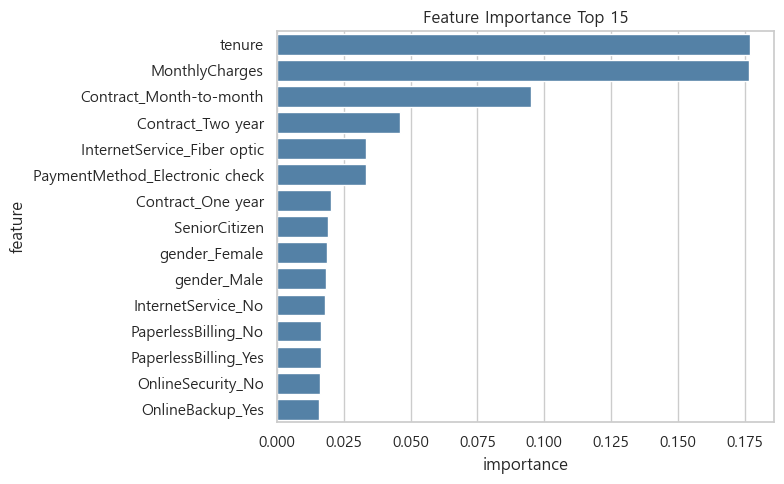

100%|██████████| 5/5 [00:00<00:00, 41.60it/s]


[mRMR] k=5 | CV F1=0.5240


100%|██████████| 10/10 [00:00<00:00, 36.42it/s]


[mRMR] k=10 | CV F1=0.5395


100%|██████████| 15/15 [00:00<00:00, 36.60it/s]


...

100%|██████████| 30/30 [00:00<00:00, 32.94it/s]


[mRMR] k=30 | CV F1=0.5323

[mRMR] 최적 k=10, CV F1=0.5395
선택 변수 (10개): ['Contract_Month-to-month', 'MonthlyCharges', 'PaymentMethod_Electronic check', 'tenure', 'InternetService_Fiber optic', 'Contract_Two year', 'PaperlessBilling_No', 'Dependents_No', 'Contract_One year', 'OnlineSecurity_No']

[Boruta] 확정 변수 (2개): ['tenure', 'MonthlyCharges']
[Boruta] 미정 변수 (0개): []
[Boruta] 기각 변수 (35개)

===== 변수 선택 방법별 요약 =====


,Method,N_features,Selected_features
0,Feature Importance,20,"[tenure, MonthlyCharges, Contract_Month-to-mon..."
1,mRMR,10,"[Contract_Month-to-month, MonthlyCharges, Paym..."
2,Boruta,2,"[tenure, MonthlyCharges]"



===== 방법 간 변수 겹침 =====


,비교,변수 수,변수 목록
0,3개 방법 공통,2,"[MonthlyCharges, tenure]"
1,FI ∩ mRMR,9,"[Contract_Month-to-month, Contract_One year, C..."
2,FI ∩ Boruta,2,"[MonthlyCharges, tenure]"
3,mRMR ∩ Boruta,2,"[MonthlyCharges, tenure]"
4,FI만 선택,11,"[InternetService_No, OnlineBackup_Yes, OnlineS..."
5,mRMR만 선택,1,[Dependents_No]
6,Boruta만 선택,0,[]


In [16]:
# ===== 변수 선택: Feature Importance / mRMR / Boruta =====
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import f1_score
from mrmr import mrmr_classif
from boruta import BorutaPy

RANDOM_STATE = 42
k_candidates = [5, 10, 15, 20, 25, 30]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ─────────────────────────────────────────────
# 1) Feature Importance (RF 중요도 상위 k, CV로 k 선택)
# ─────────────────────────────────────────────
rf_fi = RandomForestClassifier(
    n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced", n_jobs=-1
)
rf_fi.fit(X_train, y_train)

importance_df = (
    pd.DataFrame({"feature": X_train.columns, "importance": rf_fi.feature_importances_})
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

ranked_features = importance_df["feature"].tolist()

fi_results = []
for k in k_candidates:
    selected = ranked_features[:k]
    f1_list = []

    for tr_idx, va_idx in skf.split(X_train, y_train):
        rf = RandomForestClassifier(
            n_estimators=100, random_state=RANDOM_STATE, class_weight="balanced"
        )
        rf.fit(X_train.iloc[tr_idx][selected], y_train.iloc[tr_idx])
        pred = rf.predict(X_train.iloc[va_idx][selected])
        f1_list.append(f1_score(y_train.iloc[va_idx], pred, zero_division=0))

    fi_results.append({
        "k": k,
        "CV F1": round(np.mean(f1_list), 4),
        "selected_features": selected,
    })

fi_cv_df = pd.DataFrame(fi_results)[["k", "CV F1"]]
best_k_fi = int(fi_cv_df.loc[fi_cv_df["CV F1"].idxmax(), "k"])
selected_fi = [r["selected_features"] for r in fi_results if r["k"] == best_k_fi][0]

print(f"[Feature Importance] 최적 k={best_k_fi}, CV F1={fi_cv_df['CV F1'].max():.4f}")
print(f"선택 변수 ({len(selected_fi)}개):", selected_fi)

# 중요도 Top 15 시각화
plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df.head(15), x="importance", y="feature", color="steelblue")
plt.title("Feature Importance Top 15")
plt.tight_layout()
plt.show()

# ─────────────────────────────────────────────
# 2) mRMR
# ─────────────────────────────────────────────
mrmr_results = []
for k in k_candidates:
    selected = mrmr_classif(X=X_train, y=y_train, K=k)
    f1_list = []

    for tr_idx, va_idx in skf.split(X_train, y_train):
        rf = RandomForestClassifier(
            n_estimators=100, random_state=RANDOM_STATE, class_weight="balanced"
        )
        rf.fit(X_train.iloc[tr_idx][selected], y_train.iloc[tr_idx])
        pred = rf.predict(X_train.iloc[va_idx][selected])
        f1_list.append(f1_score(y_train.iloc[va_idx], pred, zero_division=0))

    mrmr_results.append({
        "k": k,
        "CV F1": round(np.mean(f1_list), 4),
        "selected_features": selected,
    })
    print(f"[mRMR] k={k} | CV F1={np.mean(f1_list):.4f}")

mrmr_cv_df = pd.DataFrame(mrmr_results)[["k", "CV F1"]]
best_k_mrmr = int(mrmr_cv_df.loc[mrmr_cv_df["CV F1"].idxmax(), "k"])
selected_mrmr = [r["selected_features"] for r in mrmr_results if r["k"] == best_k_mrmr][0]

print(f"\n[mRMR] 최적 k={best_k_mrmr}, CV F1={mrmr_cv_df['CV F1'].max():.4f}")
print(f"선택 변수 ({len(selected_mrmr)}개):", selected_mrmr)

# ─────────────────────────────────────────────
# 3) Boruta
# ─────────────────────────────────────────────
rf_boruta = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)

boruta = BorutaPy(
    rf_boruta,
    n_estimators="auto",
    max_iter=100,     # 느리면 50으로 줄이기
    perc=100,
    random_state=RANDOM_STATE,
)

boruta.fit(X_train.values, y_train.values.ravel())

selected_boruta = X_train.columns[boruta.support_].tolist()
tentative_boruta = X_train.columns[boruta.support_weak_].tolist()
rejected_boruta = X_train.columns[~boruta.support_ & ~boruta.support_weak_].tolist()

print(f"\n[Boruta] 확정 변수 ({len(selected_boruta)}개):", selected_boruta)
print(f"[Boruta] 미정 변수 ({len(tentative_boruta)}개):", tentative_boruta)
print(f"[Boruta] 기각 변수 ({len(rejected_boruta)}개)")

# ─────────────────────────────────────────────
# 4) 3가지 방법 비교 요약
# ─────────────────────────────────────────────
feature_sets = {
    "Feature Importance": selected_fi,
    "mRMR": selected_mrmr,
    "Boruta": selected_boruta,
}

summary_rows = []
for method, feats in feature_sets.items():
    summary_rows.append({
        "Method": method,
        "N_features": len(feats),
        "Selected_features": feats,
    })

feature_summary_df = pd.DataFrame(summary_rows)
print("\n===== 변수 선택 방법별 요약 =====")
display(feature_summary_df[["Method", "N_features", "Selected_features"]])

# 방법 간 교집합
fi_set = set(selected_fi)
mrmr_set = set(selected_mrmr)
boruta_set = set(selected_boruta)

overlap_df = pd.DataFrame({
    "비교": [
        "3개 방법 공통",
        "FI ∩ mRMR",
        "FI ∩ Boruta",
        "mRMR ∩ Boruta",
        "FI만 선택",
        "mRMR만 선택",
        "Boruta만 선택",
    ],
    "변수 수": [
        len(fi_set & mrmr_set & boruta_set),
        len(fi_set & mrmr_set),
        len(fi_set & boruta_set),
        len(mrmr_set & boruta_set),
        len(fi_set - mrmr_set - boruta_set),
        len(mrmr_set - fi_set - boruta_set),
        len(boruta_set - fi_set - mrmr_set),
    ],
    "변수 목록": [
        sorted(fi_set & mrmr_set & boruta_set),
        sorted(fi_set & mrmr_set),
        sorted(fi_set & boruta_set),
        sorted(mrmr_set & boruta_set),
        sorted(fi_set - mrmr_set - boruta_set),
        sorted(mrmr_set - fi_set - boruta_set),
        sorted(boruta_set - fi_set - mrmr_set),
    ],
})

print("\n===== 방법 간 변수 겹침 =====")
display(overlap_df)

# 이후 모델링에 바로 쓸 수 있도록 저장
# feature_sets["mRMR"] → X_train[feature_sets["mRMR"]] 형태로 사용

In [19]:
# ===== 변수 선택법 × (XGB / LGBM / CatBoost / Ensemble) GridSearchCV =====
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.ensemble import VotingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

RANDOM_STATE = 42
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# ----- 평가 함수 -----
def get_metrics(y_true, y_pred, y_proba):
    return {
        "Accuracy":  accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall":    recall_score(y_true, y_pred, zero_division=0),
        "F1-score":  f1_score(y_true, y_pred, zero_division=0),
        "AUC-ROC":   roc_auc_score(y_true, y_proba),
    }

def evaluate_model(model, X, y):
    y_pred = model.predict(X)
    y_proba = model.predict_proba(X)[:, 1]
    return get_metrics(y, y_pred, y_proba)

# ----- 개별 모델 GridSearch 설정 -----
def get_model_configs():
    return {
        "XGBoost": {
            "estimator": XGBClassifier(
                random_state=RANDOM_STATE,
                eval_metric="logloss",
                scale_pos_weight=scale_pos_weight,
                n_jobs=-1,
            ),
            "param_grid": {
                "n_estimators": [100, 300],
                "learning_rate": [0.01, 0.05, 0.1],
                "max_depth": [3, 5],
                "gamma": [0, 2],
                "reg_lambda": [1, 5],
                "subsample": [0.8, 1.0],
            },
        },
        "LightGBM": {
            "estimator": LGBMClassifier(
                random_state=RANDOM_STATE,
                subsample_freq=1,
                verbose=-1,
                class_weight="balanced",
            ),
            "param_grid": {
                "n_estimators": [100, 300],
                "learning_rate": [0.01, 0.05, 0.1],
                "max_depth": [3, 5],
                "num_leaves": [15, 31],
                "min_child_samples": [20, 50],
                "subsample": [0.8, 1.0],
            },
        },
        "CatBoost": {
            "estimator": CatBoostClassifier(
                random_state=RANDOM_STATE,
                verbose=0,
                bootstrap_type="Bernoulli",
                auto_class_weights="Balanced",
            ),
            "param_grid": {
                "n_estimators": [100, 300],
                "learning_rate": [0.01, 0.05, 0.1],
                "max_depth": [3, 5],
                "l2_leaf_reg": [1, 3, 5],
                "subsample": [0.8, 1.0],
            },
        },
    }

model_configs = get_model_configs()

# ----- 메인 Loop -----
all_results = []
best_model_store = {}   # (feature_set, model_name) -> best_estimator

for fs_name, features in feature_sets.items():
  if len(features) == 0:
      print(f"[SKIP] {fs_name}: 선택 변수 0개")
      continue

  print("\n" + "=" * 70)
  print(f"[Feature Set] {fs_name} | 변수 수: {len(features)}")
  print("=" * 70)

  X_tr = X_train[features]
  X_v  = X_val[features]
  X_te = X_test[features]

  tuned_for_ensemble = {}

  # 1) XGB / LGBM / CatBoost 개별 튜닝
  for model_name, cfg in model_configs.items():
      print(f"\n--- {model_name} GridSearchCV ---")

      grid = GridSearchCV(
          estimator=cfg["estimator"],
          param_grid=cfg["param_grid"],
          cv=cv,
          scoring="roc_auc",
          n_jobs=-1,
          refit=True,
      )
      grid.fit(X_tr, y_train)

      best_model = grid.best_estimator_
      best_model_store[(fs_name, model_name)] = best_model
      tuned_for_ensemble[model_name] = best_model

      val_metrics  = evaluate_model(best_model, X_v, y_val)
      test_metrics = evaluate_model(best_model, X_te, y_test)

      all_results.append({
          "Feature_Set": fs_name,
          "N_features": len(features),
          "Model": model_name,
          "Best_CV_AUC": round(grid.best_score_, 4),
          "Best_Params": grid.best_params_,
          **{f"Val_{k}": v for k, v in val_metrics.items()},
          **{f"Test_{k}": v for k, v in test_metrics.items()},
      })

      print(f"Best CV AUC: {grid.best_score_:.4f}")
      print(f"Val AUC-ROC: {val_metrics['AUC-ROC']:.4f}")

  # 2) 앙상블 (튜닝된 3개 Soft Voting)
  print(f"\n--- Ensemble (Soft Voting) ---")
  estimators = [
      (name.replace(" ", "_"), model)
      for name, model in tuned_for_ensemble.items()
  ]

  voting_clf = VotingClassifier(
      estimators=estimators,
      voting="soft",
      n_jobs=-1,
  )
  voting_clf.fit(X_tr, y_train)

  best_model_store[(fs_name, "Ensemble")] = voting_clf

  val_metrics  = evaluate_model(voting_clf, X_v, y_val)
  test_metrics = evaluate_model(voting_clf, X_te, y_test)

  all_results.append({
      "Feature_Set": fs_name,
      "N_features": len(features),
      "Model": "Ensemble (Voting)",
      "Best_CV_AUC": np.nan,
      "Best_Params": "Soft Voting of tuned XGB/LGBM/CatBoost",
      **{f"Val_{k}": v for k, v in val_metrics.items()},
      **{f"Test_{k}": v for k, v in test_metrics.items()},
  })

  print(f"Val AUC-ROC: {val_metrics['AUC-ROC']:.4f}")

# ----- 결과 정리 -----
results_df = pd.DataFrame(all_results)

# Validation 성능 비교표
val_cols = ["Feature_Set", "N_features", "Model", "Best_CV_AUC",
            "Val_Accuracy", "Val_Precision", "Val_Recall", "Val_F1-score", "Val_AUC-ROC"]
val_compare_df = (
    results_df[val_cols]
    .sort_values(["Feature_Set", "Val_AUC-ROC"], ascending=[True, False])
    .round(4)
)

print("\n===== Validation 성능 비교 (변수선택 × 모델) =====")
display(val_compare_df)

# Test 성능 비교표
test_cols = ["Feature_Set", "N_features", "Model",
             "Test_Accuracy", "Test_Precision", "Test_Recall", "Test_F1-score", "Test_AUC-ROC"]
test_compare_df = (
    results_df[test_cols]
    .sort_values(["Feature_Set", "Test_AUC-ROC"], ascending=[True, False])
    .round(4)
)

print("\n===== Test 최종 성능 비교 =====")
display(test_compare_df)

# Feature Set별 최고 모델
best_per_fs_val = (
    val_compare_df.sort_values("Val_AUC-ROC", ascending=False)
    .groupby("Feature_Set", as_index=False)
    .first()
)
print("\n===== Feature Set별 Validation 최고 모델 =====")
display(best_per_fs_val)

# 전체 최고 조합
best_row = val_compare_df.loc[val_compare_df["Val_AUC-ROC"].idxmax()]
print("\n===== Validation 기준 전체 최고 조합 =====")
display(best_row.to_frame().T)

# 이후 재사용: best_model_store[(feature_set명, 모델명)]


[Feature Set] Feature Importance | 변수 수: 20

--- XGBoost GridSearchCV ---
Best CV AUC: 0.8491
Val AUC-ROC: 0.8397

--- LightGBM GridSearchCV ---
Best CV AUC: 0.8486
Val AUC-ROC: 0.8411

--- CatBoost GridSearchCV ---
Best CV AUC: 0.8496
Val AUC-ROC: 0.8399

--- Ensemble (Soft Voting) ---
Val AUC-ROC: 0.8407

[Feature Set] mRMR | 변수 수: 10

--- XGBoost GridSearchCV ---
Best CV AUC: 0.8471
Val AUC-ROC: 0.8377

--- LightGBM GridSearchCV ---
Best CV AUC: 0.8469
Val AUC-ROC: 0.8376

--- CatBoost GridSearchCV ---
Best CV AUC: 0.8485
Val AUC-ROC: 0.8394

--- Ensemble (Soft Voting) ---
Val AUC-ROC: 0.8390

[Feature Set] Boruta | 변수 수: 2

--- XGBoost GridSearchCV ---
Best CV AUC: 0.8230
Val AUC-ROC: 0.8081

--- LightGBM GridSearchCV ---
Best CV AUC: 0.8232
Val AUC-ROC: 0.8082

--- CatBoost GridSearchCV ---
Best CV AUC: 0.8246
Val AUC-ROC: 0.8057

--- Ensemble (Soft Voting) ---
Val AUC-ROC: 0.8076

===== Validation 성능 비교 (변수선택 × 모델) =====


,Feature_Set,N_features,Model,Best_CV_AUC,Val_Accuracy,Val_Precision,Val_Recall,Val_F1-score,Val_AUC-ROC
9,Boruta,2,LightGBM,0.8232,0.7055,0.4668,0.7701,0.5812,0.8082
8,Boruta,2,XGBoost,0.8230,0.7076,0.4686,0.7594,0.5796,0.8081
11,Boruta,2,Ensemble (Voting),NaN,0.7126,0.4744,0.7674,0.5863,0.8076
10,Boruta,2,CatBoost,0.8246,0.7147,0.4767,0.7647,0.5873,0.8057
1,Feature Importance,20,LightGBM,0.8486,0.7424,0.5093,0.8048,0.6238,0.8411
3,Feature Importance,20,Ensemble (Voting),NaN,0.7410,0.5075,0.8128,0.6249,0.8407
2,Feature Importance,20,CatBoost,0.8496,0.7410,0.5075,0.8182,0.6264,0.8399
0,Feature Importance,20,XGBoost,0.8491,0.7353,0.5008,0.8102,0.6190,0.8397
6,mRMR,10,CatBoost,0.8485,0.7438,0.5111,0.8021,0.6243,0.8394
7,mRMR,10,Ensemble (Voting),NaN,0.7360,0.5017,0.7968,0.6157,0.8390



===== Test 최종 성능 비교 =====


,Feature_Set,N_features,Model,Test_Accuracy,Test_Precision,Test_Recall,Test_F1-score,Test_AUC-ROC
10,Boruta,2,CatBoost,0.7260,0.4901,0.7968,0.6069,0.8264
11,Boruta,2,Ensemble (Voting),0.7239,0.4876,0.7888,0.6027,0.8245
8,Boruta,2,XGBoost,0.7175,0.4805,0.7888,0.5972,0.8230
9,Boruta,2,LightGBM,0.7211,0.4845,0.7914,0.6010,0.8225
2,Feature Importance,20,CatBoost,0.7374,0.5033,0.8048,0.6193,0.8462
3,Feature Importance,20,Ensemble (Voting),0.7445,0.5118,0.8102,0.6273,0.8451
0,Feature Importance,20,XGBoost,0.7445,0.5120,0.7995,0.6242,0.8449
1,Feature Importance,20,LightGBM,0.7445,0.5119,0.8048,0.6258,0.8432
6,mRMR,10,CatBoost,0.7410,0.5077,0.7968,0.6202,0.8430
7,mRMR,10,Ensemble (Voting),0.7438,0.5111,0.7995,0.6236,0.8423



===== Feature Set별 Validation 최고 모델 =====


,Feature_Set,N_features,Model,Best_CV_AUC,Val_Accuracy,Val_Precision,Val_Recall,Val_F1-score,Val_AUC-ROC
0,Boruta,2,LightGBM,0.8232,0.7055,0.4668,0.7701,0.5812,0.8082
1,Feature Importance,20,LightGBM,0.8486,0.7424,0.5093,0.8048,0.6238,0.8411
2,mRMR,10,CatBoost,0.8485,0.7438,0.5111,0.8021,0.6243,0.8394



===== Validation 기준 전체 최고 조합 =====


,Feature_Set,N_features,Model,Best_CV_AUC,Val_Accuracy,Val_Precision,Val_Recall,Val_F1-score,Val_AUC-ROC
1,Feature Importance,20,LightGBM,0.8486,0.7424,0.5093,0.8048,0.6238,0.8411


**[과제]** 써니는 클래스 불균형을 완화하면 모델 성능이 향상될 것이라고 생각했습니다.

AI와 상의하여 Resampling (TomekLinks, SMOTE, TomekLinks+SMOTE, ADASYN 등) 또는 One-Class Learning (SVDD 등) 중 본 데이터에 적합한 방법을 선택하고 적용해 보세요.

이후 적용 전후의 모델 성능을 비교해 보세요.

In [ ]:
# ===== 클래스 불균형 해소: Feature Importance 최적 조합에 적용 =====
# 앞 실험에서 F1이 가장 좋았던 "Feature Importance 변수 + 해당 조합 최적 모델/파라미터"를
# base 모델로 그대로 사용하고, 불균형 해소(리샘플링/가중치) 효과를 비교한다.
# ※ Resampling은 Train에만 적용 / Val·Test는 원본 불균형 유지

from sklearn.base import clone
from imblearn.under_sampling import TomekLinks
from imblearn.combine import SMOTETomek
from imblearn.pipeline import Pipeline as ImbPipeline

# --- 0) 앞 단계 산출물 확인 (변수 선택 셀 + 변수선택×모델 GridSearch 셀 필요) ---
assert "feature_sets" in globals() and "best_model_store" in globals(), \
    "먼저 변수 선택 셀과 (변수선택 × 모델) GridSearch 셀을 실행하세요."

# Feature Importance 선택 변수
fi_features = feature_sets["Feature Importance"]

# Feature Importance 조합에서 Validation AUC 기준 최적 단일 모델 선택 (앙상블 제외)
fi_candidates = {
    model_name: model
    for (fs_name, model_name), model in best_model_store.items()
    if fs_name == "Feature Importance" and model_name != "Ensemble"
}
assert len(fi_candidates) > 0, "best_model_store에 Feature Importance 단일 모델이 없습니다."

best_fi_name = max(
    fi_candidates,
    key=lambda name: roc_auc_score(
        y_val, fi_candidates[name].predict_proba(X_val[fi_features])[:, 1]
    ),
)
base_tuned = clone(fi_candidates[best_fi_name])   # 튜닝된 파라미터 그대로 (클래스 가중치 포함)

print(f"선택된 최적 조합: Feature Importance + {best_fi_name}")
print(f"사용 변수 개수: {len(fi_features)}")
print("적용 파라미터:", base_tuned.get_params())

# 리샘플링 효과만 분리해서 보기 위해 내장 클래스 가중치를 제거한 버전
def neutralize_class_weight(model):
    m = clone(model)
    params = m.get_params()
    if "class_weight" in params:
        m.set_params(class_weight=None)
    if "scale_pos_weight" in params:
        m.set_params(scale_pos_weight=1)
    if "auto_class_weights" in params:
        m.set_params(auto_class_weights=None)
    return m

base_neutral = neutralize_class_weight(base_tuned)

# --- 1) FI 변수로 데이터 한정 + Train 클래스 분포 ---
X_train_fi, X_val_fi, X_test_fi = X_train[fi_features], X_val[fi_features], X_test[fi_features]

print("\n===== Train 클래스 분포 (Resampling 적용 전) =====")
print(y_train.value_counts())
print(y_train.value_counts(normalize=True).round(3))

# --- 2) 평가 함수 ---
def evaluate_classifier(y_true, y_pred, y_proba):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_true, y_proba),
    }

def run_experiment(pipeline, X_tr, y_tr, X_va, y_va, X_te, y_te):
    pipeline.fit(X_tr, y_tr)
    val_pred = pipeline.predict(X_va)
    val_proba = pipeline.predict_proba(X_va)[:, 1]
    test_pred = pipeline.predict(X_te)
    test_proba = pipeline.predict_proba(X_te)[:, 1]

    val_metrics = evaluate_classifier(y_va, val_pred, val_proba)
    test_metrics = evaluate_classifier(y_te, test_pred, test_proba)
    return val_metrics, test_metrics

# --- 3) 불균형 해소 방법별 파이프라인 (base = FI 최적 모델) ---
# (0) Baseline: 불균형 해소 없음 (가중치 제거)
baseline_pipe = ImbPipeline([
    ("scaler", StandardScaler()),
    ("model", clone(base_neutral)),
])

# (1) 튜닝된 클래스 가중치 그대로
weighted_pipe = ImbPipeline([
    ("scaler", StandardScaler()),
    ("model", clone(base_tuned)),
])

# (2) SMOTE + TomekLinks
smote_tomek_pipe = ImbPipeline([
    ("scaler", StandardScaler()),
    ("resample", SMOTETomek(random_state=RANDOM_STATE)),
    ("model", clone(base_neutral)),
])

# (3) TomekLinks 단독
tomek_pipe = ImbPipeline([
    ("scaler", StandardScaler()),
    ("resample", TomekLinks()),
    ("model", clone(base_neutral)),
])

experiments = {
    "Baseline (적용 전)": baseline_pipe,
    "튜닝 클래스 가중치": weighted_pipe,
    "SMOTE + TomekLinks": smote_tomek_pipe,
    "TomekLinks": tomek_pipe,
}

# --- 4) Resampling 후 Train 크기 확인 (Train에만 적용) ---
print("\n===== Resampling 후 Train 크기 =====")
scaler_tmp = StandardScaler()
X_train_fi_scaled = scaler_tmp.fit_transform(X_train_fi)

for resample_name, resampler in [
    ("TomekLinks", TomekLinks()),
    ("SMOTE + TomekLinks", SMOTETomek(random_state=RANDOM_STATE)),
]:
    X_res, y_res = resampler.fit_resample(X_train_fi_scaled, y_train)
    print(f"\n[{resample_name}]")
    print(f"  샘플 수: {len(y_res)} (적용 전 {len(y_train)})")
    print(pd.Series(y_res).value_counts())

# --- 5) Validation / Test 성능 비교 ---
val_results, test_results = [], []

for name, pipe in experiments.items():
    val_m, test_m = run_experiment(pipe, X_train_fi, y_train, X_val_fi, y_val, X_test_fi, y_test)
    val_results.append({"Method": name, **val_m})
    test_results.append({"Method": name, **test_m})

val_df = pd.DataFrame(val_results).set_index("Method").round(4)
test_df = pd.DataFrame(test_results).set_index("Method").round(4)

print(f"\n===== Validation 성능 비교 (Feature Importance + {best_fi_name}) =====")
display(val_df)

print(f"\n===== Test 성능 비교 (Feature Importance + {best_fi_name}) =====")
display(test_df)

# --- 6) Baseline 대비 F1-score 변화 ---
print("\n===== Baseline 대비 F1-score 변화 (Test) =====")
baseline_f1 = test_df.loc["Baseline (적용 전)", "F1-score"]
for method in test_df.index:
    if method == "Baseline (적용 전)":
        continue
    diff = test_df.loc[method, "F1-score"] - baseline_f1
    sign = "+" if diff >= 0 else ""
    print(f"  {method:20s}: {sign}{diff:.4f}")

## 6) 모델 해석

1. SHAP Value
2. Clustering 기반 RCA
3. STUCCO 기반 RCA

**[과제]** 써니는 최종 모델의 예측 결과를 해석하고자 합니다.

가장 예측력이 좋았던 전처리 방법, 모델, 모델 고도화 방법의 조합을 선택한 뒤, AI와 상의하여 적절한 모델 해석 기법을 적용해 보세요.

이를 바탕으로 "어떤 고객이 채무불이행 위험이 높은지"를 한 문단으로 정리해 보세요.